In [1]:
# Import Seaborn library
import seaborn as sns

# Load the Taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
# Check for missing values in each column
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [3]:
# Fill missing payment values using mode
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

# Remove rows with missing critical location values
df = df.dropna(subset=[
    'pickup_zone',
    'dropoff_zone',
    'pickup_borough',
    'dropoff_borough'
])

# Check missing values again
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

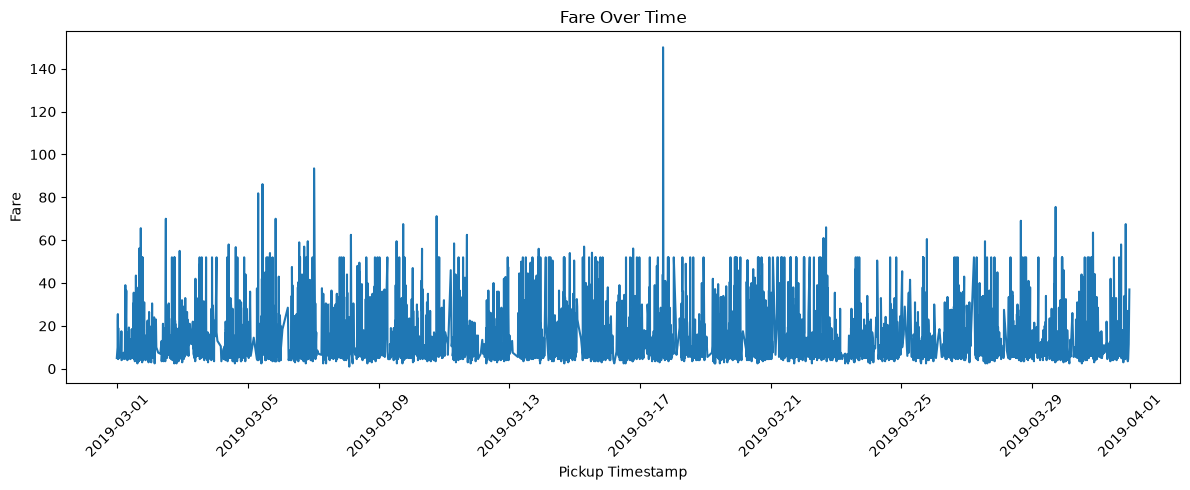

In [4]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

# Convert pickup column to datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort data by pickup timestamp
df = df.sort_values('pickup')

# Create line chart
plt.figure(figsize=(12, 5))
plt.plot(df['pickup'], df['fare'])

# Add title and labels
plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

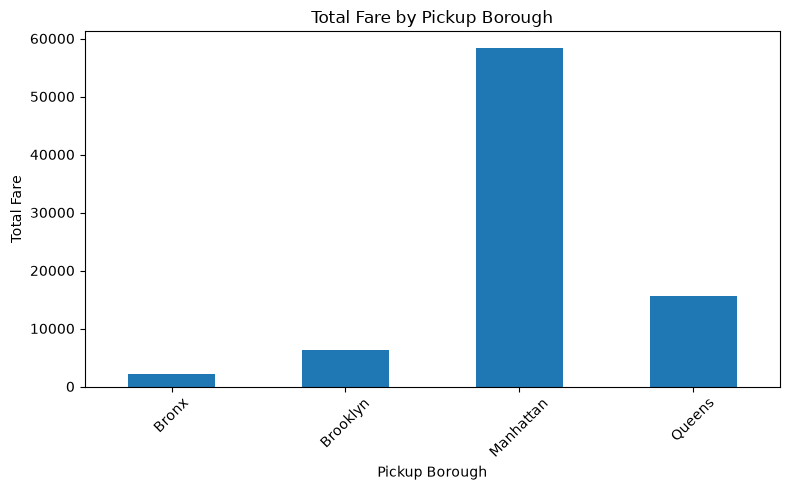

In [5]:
# Calculate total fare for each pickup borough
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(8, 5))
borough_fare.plot(kind='bar')

# Add title and labels
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

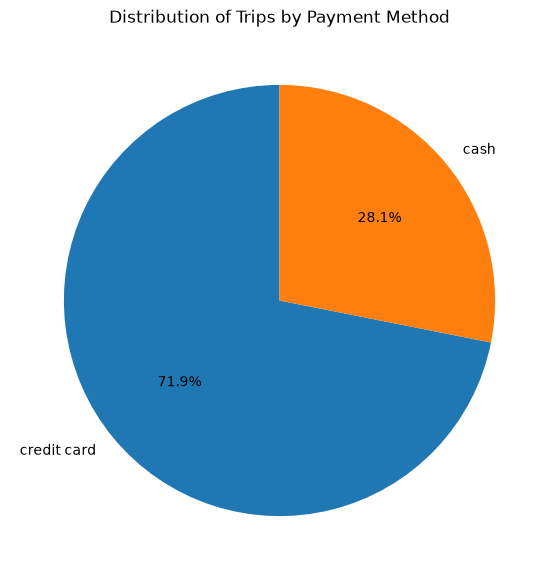

In [6]:
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

# Add title
plt.title('Distribution of Trips by Payment Method')

# Display chart
plt.show()

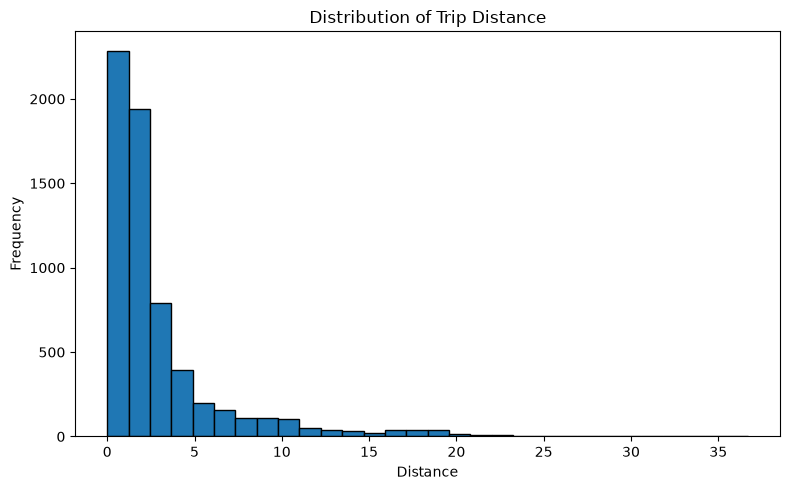

In [7]:
# Create histogram for trip distance
plt.figure(figsize=(8, 5))

plt.hist(df['distance'], bins=30, edgecolor='black')

# Add title and labels
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

# Display histogram
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

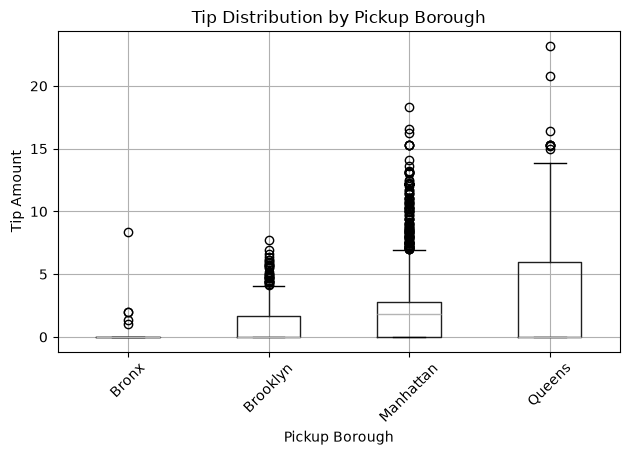

In [8]:
# Create box plot for tip amounts by pickup borough
plt.figure(figsize=(9, 5))

df.boxplot(column='tip', by='pickup_borough')

# Add title and labels
plt.title('Tip Distribution by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

# Display box plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

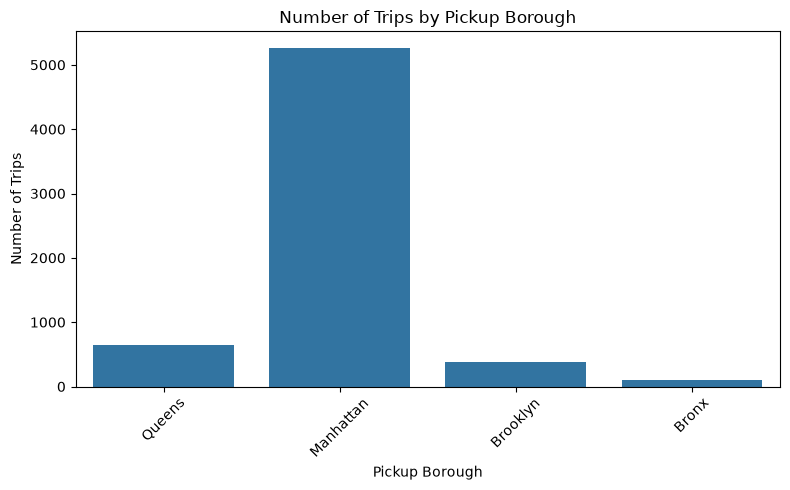

In [9]:
# Create count plot
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='pickup_borough')

# Add title and labels
plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

# Display plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

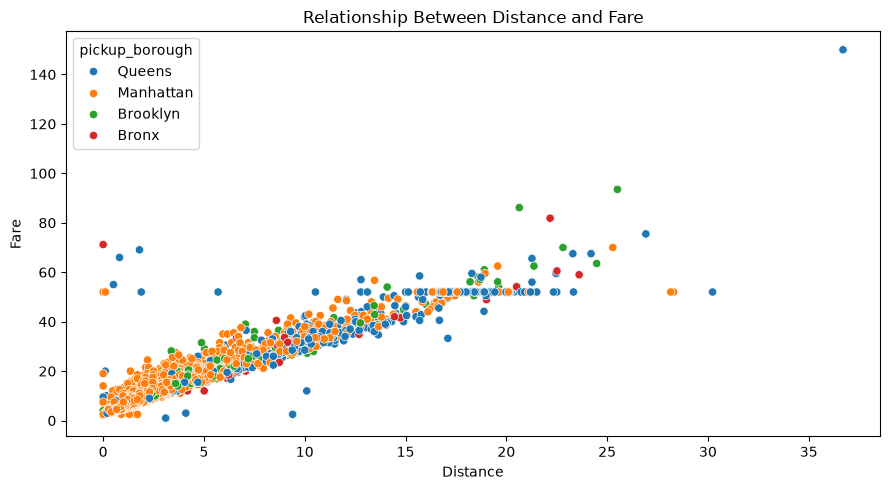

In [10]:
# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

# Add title and labels
plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

# Display plot
plt.tight_layout()
plt.show()

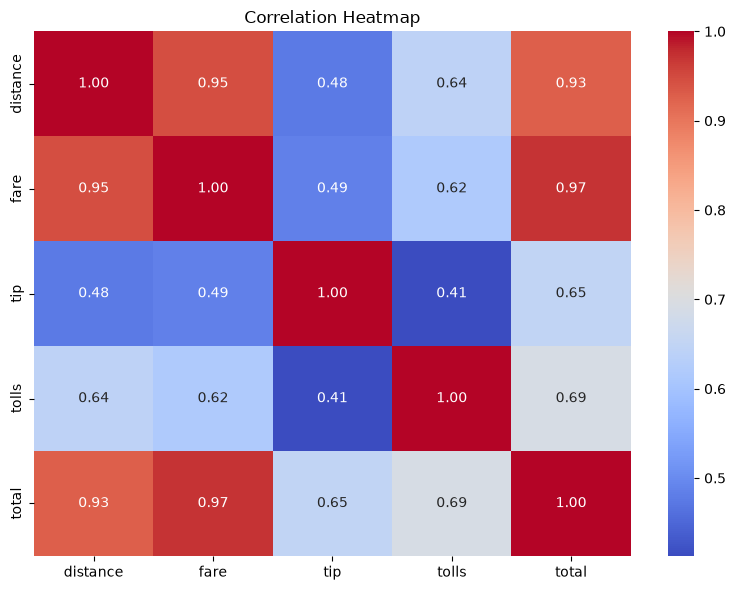

In [11]:
# Select numerical columns
numeric_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

# Add title
plt.title('Correlation Heatmap')

# Display heatmap
plt.tight_layout()
plt.show()

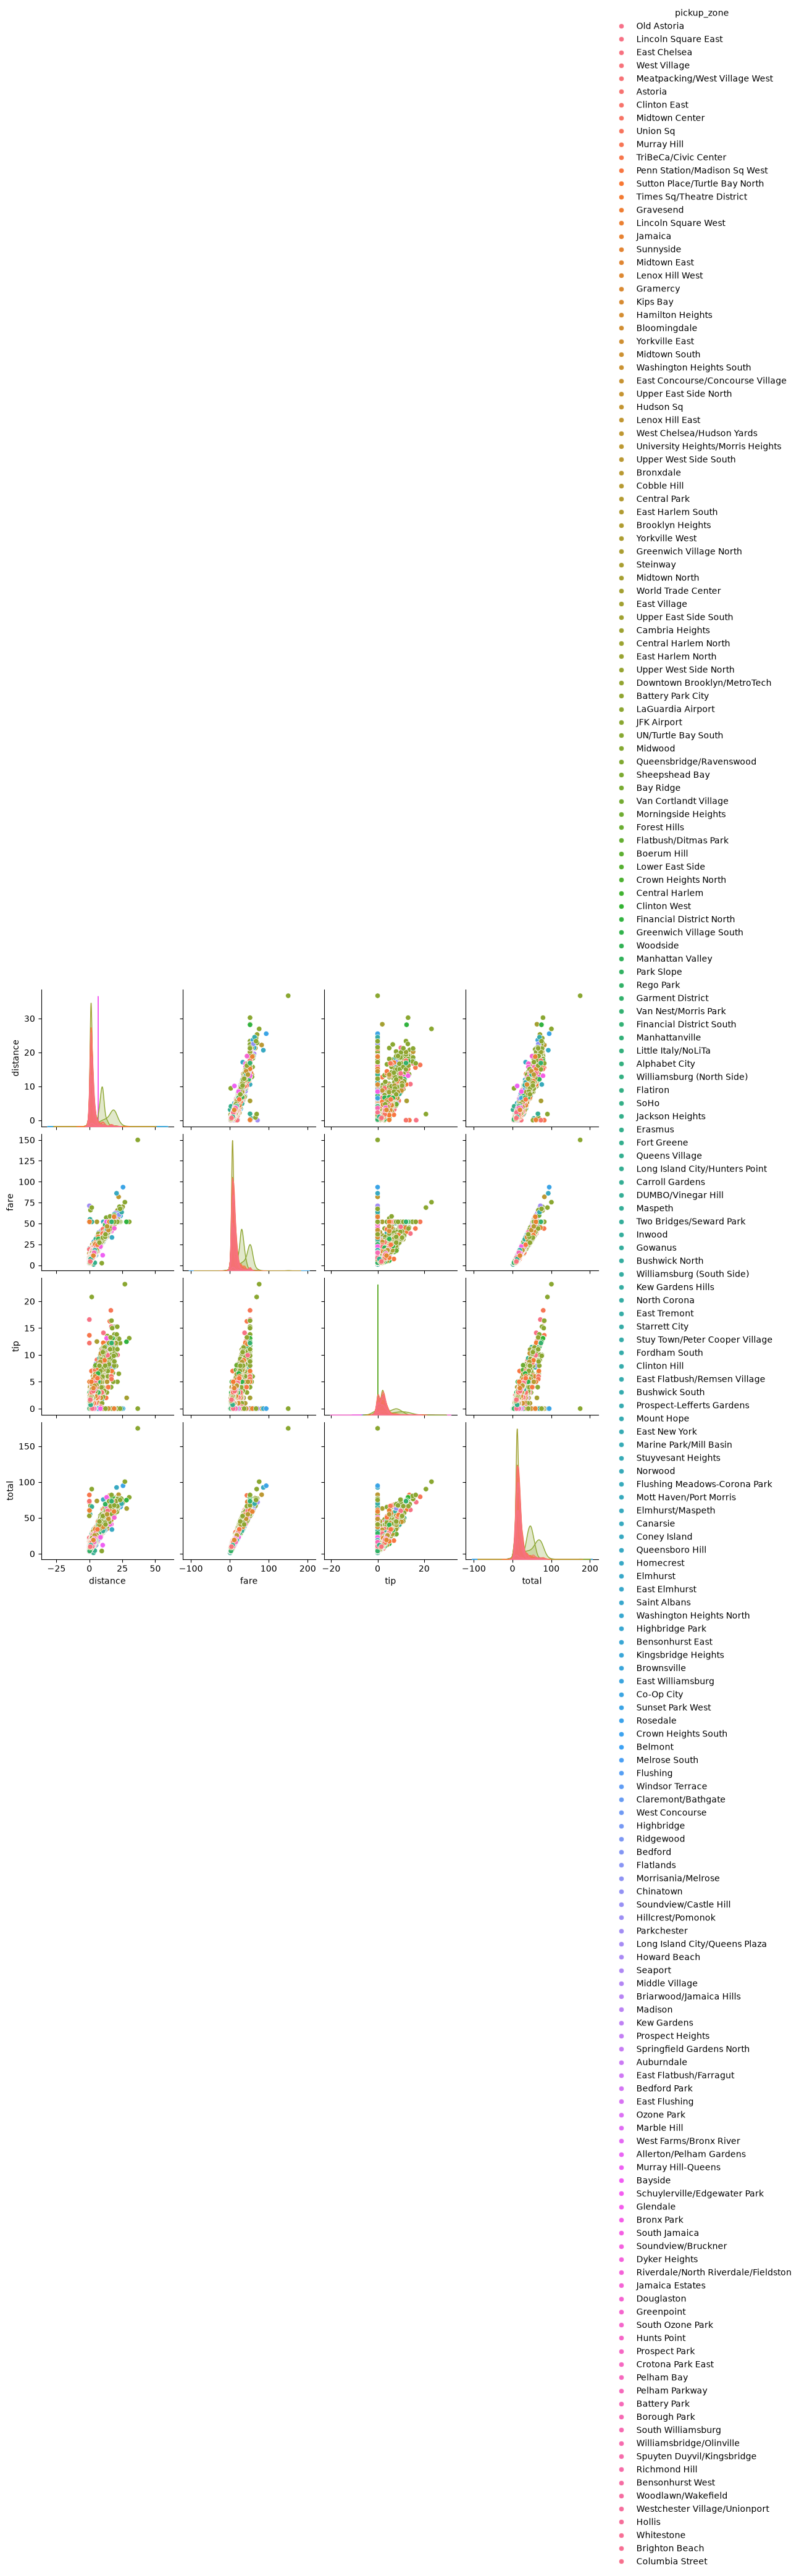

In [12]:
# Create pair plot
sns.pairplot(
    data=df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

# Display pair plot
plt.show()

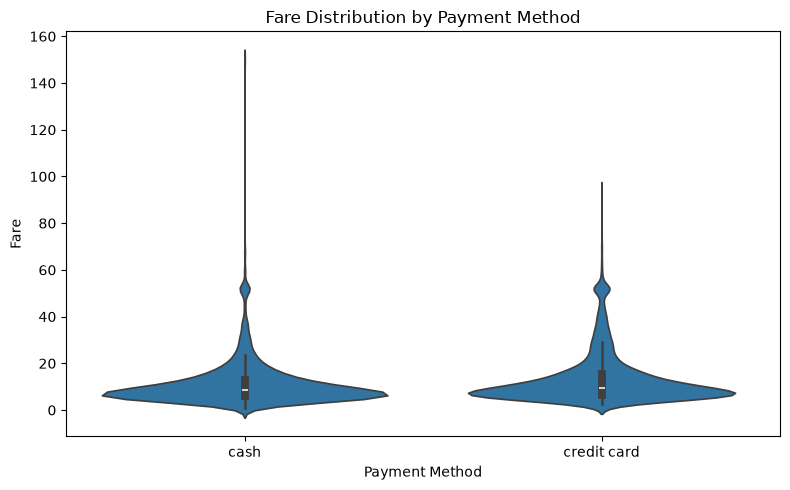

In [13]:
# Create violin plot
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

# Add title and labels
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

# Display plot
plt.tight_layout()
plt.show()